In [1]:
# conda env 'vis2'
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent.parent.parent
V = 'V06'
VERSION = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / V
INTERIM_DATA = PROJECT_ROOT / 'data' / 'interim'
FIGURE_OUT = PROJECT_ROOT / 'figures'

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import glob
import at3d

savefigs = False
fig_version = 'V03'

In [2]:
def segment_cloud(cloud, cvm):
    cloud['volume'] = cloud.extinction > 0
    cloud['volume'].data = cloud['volume'].data.astype(np.int64)
    cloud['cth_cloud'] = cloud.volume & cvm.cth_cloud
    cloud['lcl_cloud'] = cloud.volume & cvm.lcl_cloud
    cloud['spc_cloud'] = cloud.volume & cvm.spc_cloud
    cloud['cth_clear'] = cloud.volume & cvm.cth_clear
    cloud['lcl_clear'] = cloud.volume & cvm.lcl_clear
    cloud['spc_clear'] = cloud.volume & cvm.spc_clear
    cloud['cloud'] = cloud.volume & cvm.cloud
    cloud['clear'] = cloud.volume & cvm.clear
    cloud['intersection'] = cloud.cth_cloud & cloud.lcl_cloud & cloud.spc_cloud & cloud.cth_clear & cloud.lcl_clear & cloud.spc_clear & cloud.cloud & cloud.clear
    cloud['union'] = cloud.cth_cloud | cloud.lcl_cloud | cloud.spc_cloud | cloud.cth_clear | cloud.lcl_clear | cloud.spc_clear | cloud.cloud | cloud.clear
    cloud['tau'] = cloud.extinction.integrate(['z'])
    cloud['cloud_mask'] = (cloud.tau > 0).astype(np.int64)
    cloud['cf'] = cloud.cloud_mask.sum() / (cloud.sizes['x'] * cloud.sizes['y'])
    return cloud

def set_labels(ax_flat):
    labels = ['a)', 'b)', 'c)', 'd)', 'e)', 'f)', 'g)', 'h)', 'i)']
    for i, a in enumerate(ax_flat):
        a.set_title(
            labels[i],
            fontfamily='serif',
            loc='left',
            fontsize='medium',
            fontweight='bold'
        )


In [3]:
CVM_file = INTERIM_DATA / 'CVM_CAMP2Ex_RF17_default_open.nc'

cvm = xr.load_dataset(CVM_file)
cvm['lcl_mask'].data = cvm['lcl_mask'].data.astype(np.int64)
cvm['cloud_volume_mask'].data = cvm['cloud_volume_mask'].data.astype(np.int64)
cvm['cth_mask'].data[0,:,:] = cvm['cth_mask'].data[-1,:,:] = 0
cvm['cth_mask'].data[:,0,:] = cvm['cth_mask'].data[:,-1,:] = 0
cvm['lcl_mask'].data[0,:,:] = cvm['lcl_mask'].data[-1,:,:] = 0
cvm['lcl_mask'].data[:,0,:] = cvm['lcl_mask'].data[:,-1,:] = 0
cvm['sc_mask'].data[0,:,:] = cvm['sc_mask'].data[-1,:,:] = 0
cvm['sc_mask'].data[:,0,:] = cvm['sc_mask'].data[:,-1,:] = 0
cvm['cloud_volume_mask'].data[0,:,:] = cvm['cloud_volume_mask'].data[-1,:,:] = 0
cvm['cloud_volume_mask'].data[:,0,:] = cvm['cloud_volume_mask'].data[:,-1,:] = 0

cvm['cth_cloud'] = cvm.cth_mask & np.logical_not(cvm.lcl_mask) & np.logical_not(cvm.sc_mask)
cvm['lcl_cloud'] = np.logical_not(cvm.cth_mask) & cvm.lcl_mask & np.logical_not(cvm.sc_mask)
cvm['spc_cloud'] = np.logical_not(cvm.cth_mask) & np.logical_not(cvm.lcl_mask) & cvm.sc_mask
cvm['cth_clear'] = np.logical_not(cvm.cth_mask) & cvm.lcl_mask & cvm.sc_mask
cvm['lcl_clear'] = cvm.cth_mask & np.logical_not(cvm.lcl_mask) & cvm.sc_mask
cvm['spc_clear'] = cvm.cth_mask & cvm.lcl_mask & np.logical_not(cvm.sc_mask)
cvm['cloud'] = cvm.cth_mask & cvm.lcl_mask & cvm.sc_mask
cvm['clear'] = np.logical_not(cvm.cth_mask) & np.logical_not(cvm.lcl_mask) & np.logical_not(cvm.sc_mask)
cvm['clear'].data = cvm['clear'].data.astype(np.int64)
cvm['intersection'] = cvm.cth_cloud & cvm.lcl_cloud & cvm.spc_cloud & cvm.cth_clear & cvm.lcl_clear & cvm.spc_clear & cvm.cloud & cvm.clear
cvm['union'] = cvm.cth_cloud | cvm.lcl_cloud | cvm.spc_cloud | cvm.cth_clear | cvm.lcl_clear | cvm.spc_clear | cvm.cloud | cvm.clear

cvm['cloud_mask'] = (cvm['cloud_volume_mask'].integrate(['z']) > 0).astype(np.int64)
cvm['cf'] = cvm.cloud_mask.sum() / (cvm.sizes['x'] * cvm.sizes['y'])

In [4]:
titles = [
    'default',
    'LCL + CTH',
    'Unconstrained',
    'Dark Surf Unc'
]

iter_files = [
    VERSION / 'default' / 'iterations',
    VERSION / 'CVM' / 'LCL_CTH' / 'iterations',
    VERSION / 'CVM' / 'unconstrained' / 'iterations',
    VERSION / 'CVM' / 'unconstrained_darksurf' / 'iterations'
]

clouds = {}
for title, iter_file in zip(titles, iter_files):
    files = sorted(iter_file.glob('iter*.nc'))
    sensors, solvers, rte_grid = at3d.util.load_forward_model(files[-1])
    cloud = solvers[0.67].medium['cloud']
    cloud = segment_cloud(cloud, cvm)
    clouds[title] = cloud

/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '128'. Max cell optical depth: '3.9491629600524902'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python

In [5]:
regions = ['cth_cloud', 'lcl_cloud', 'spc_cloud', 'cth_clear', 'lcl_clear', 'spc_clear', 'cloud', 'clear']
print('Cloud Volume By Region (pct of total)')
tmp = '{:<10} |'.format('Region')
for t in titles:
    tmp += ' {:<19} |'.format(t)
tmp += ' {:<20}'.format('CVM Volume')
print(tmp)
print('-'*(len(titles)*21 + 12 + 22))
for r in regions:
    tmp = '{:<10} |'.format(r)
    for t in titles:
        c = clouds[t]
        rvol = c[r].integrate(['x','y','z']).data
        tot_vol = c.volume.integrate(['x','y','z']).data
        tmp += ' {:<8.3f} ({:<7.2f}%) |'.format(rvol, 100*rvol/tot_vol)
    tmp += ' {:<20.3f}'.format(cvm[r].integrate(['x','y','z']).data)
    print(tmp)
print('-'*(len(titles)*21 + 12 + 22))
tmp = '{:<10} |'.format('TOTAL')
for t in titles:
    c = clouds[t]
    rvol = c[r].integrate(['x','y','z']).data
    tot_vol = c.volume.integrate(['x','y','z']).data
    tmp += ' {:<19.3f} |'.format(tot_vol)
tmp += ' {:<20.3f}'.format(cvm.union.integrate(['x','y','z']).data)
print(tmp)

Cloud Volume By Region (pct of total)
Region     | default             | LCL + CTH           | Unconstrained       | Dark Surf Unc       | CVM Volume          
----------------------------------------------------------------------------------------------------------------------
cth_cloud  | 0.000    (0.00   %) | 0.000    (0.00   %) | 0.019    (0.03   %) | 3.010    (1.74   %) | 12.210              
lcl_cloud  | 0.000    (0.00   %) | 0.000    (0.00   %) | 0.480    (0.67   %) | 6.303    (3.65   %) | 22.298              
spc_cloud  | 0.000    (0.00   %) | 0.000    (0.00   %) | 0.000    (0.00   %) | 0.000    (0.00   %) | 0.000               
cth_clear  | 0.000    (0.00   %) | 0.000    (0.00   %) | 37.548   (52.56  %) | 90.807   (52.56  %) | 193.328             
lcl_clear  | 0.000    (0.00   %) | 0.000    (0.00   %) | 11.484   (16.07  %) | 32.284   (18.69  %) | 92.716              
spc_clear  | 0.000    (0.00   %) | 1.891    (3.95   %) | 0.038    (0.05   %) | 2.337    (1.35   %) | 11.374    

In [6]:
## Relative Bias and Difference from WITHIN the CVM
cond = cvm.cloud_volume_mask.data == 1
ext_def = clouds['default'].extinction.data[cond]
ext_unc = clouds['Unconstrained'].extinction.data[cond]
rel_diff = 100 * (np.sum((ext_unc - ext_def)**2))**0.5 / (np.sum(ext_def)**2)**0.5
rel_bias = 100 * (np.sum(np.abs(ext_unc)) - np.sum(np.abs(ext_def))) / (np.sum(np.abs(ext_def)))

print('Relative Bias: {:.2f}'.format(rel_bias))
print('Relative Diff: {:.2f}'.format(rel_diff))

Relative Bias: -50.44
Relative Diff: 1.59


### Figure 13: Default & Unconstrained Transects

4.4


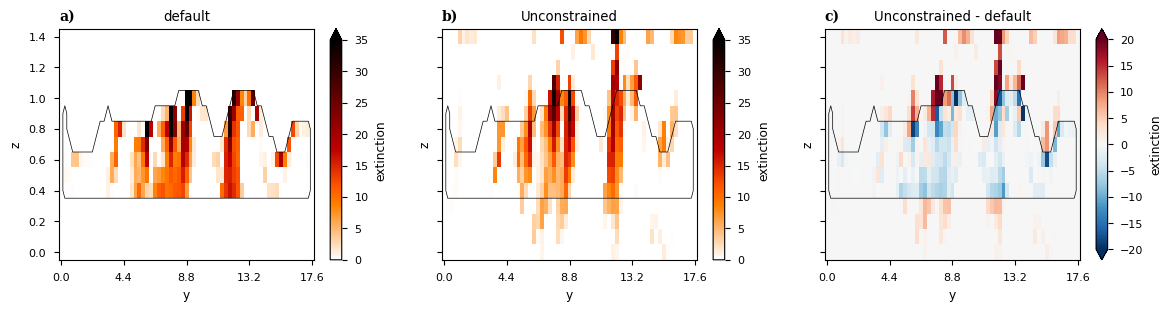

In [7]:
ref = 'default'
comp = 'Unconstrained'
ext_cmap = 'gist_heat_r'
x = 4.4
vmax = 35
ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(1, 3, figsize=(14, 3), sharey=True)
clouds[ref].sel(x=x, method='nearest').extinction.plot(y='z', ax=ax[0], vmin=0, vmax=vmax, cmap=ext_cmap)
clouds[comp].sel(x=x, method='nearest').extinction.plot(y='z', ax=ax[1], vmin=0, vmax=vmax, cmap=ext_cmap)
(clouds[comp].extinction - clouds[ref].extinction).sel(x=x, method='nearest').plot(y='z', ax=ax[2], vmin=-20, vmax=20, cmap='RdBu_r')
cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[0], colors='black', linewidths=0.5)
cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[1], colors='black', linewidths=0.5)
cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[2], colors='black', linewidths=0.5)
ax[0].set_title(ref)
ax[1].set_title(comp)
ax[2].set_title('{} - {}'.format(comp, ref))
print(cvm.sel(x=x, method='nearest').x.data)
set_labels(ax.flatten())
for a in ax.flatten():
    a.set_xticks(ticks)

if(savefigs):
    plt.savefig(
        FIGURE_OUT / '{}_figure13_default_unc_transects.png'.format(fig_version),
        format='png',
        dpi=300,
        bbox_inches='tight',
        transparent=False
    )


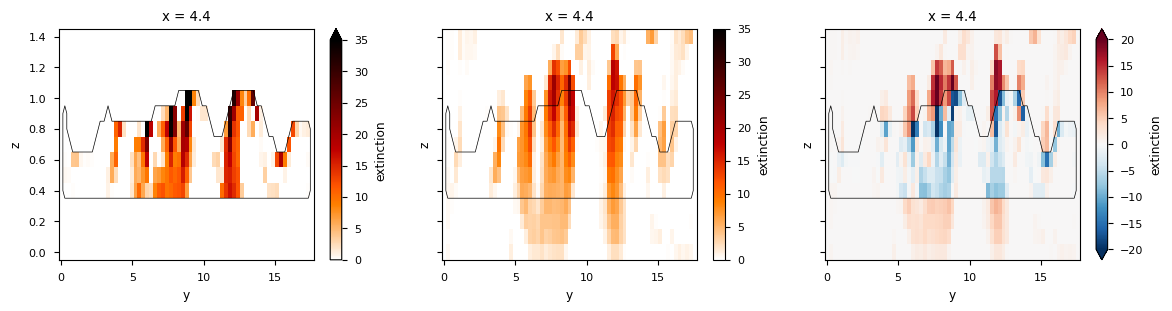

In [8]:
ref = 'default'
comp = 'Dark Surf Unc'
ext_cmap = 'gist_heat_r'
x = 4.4
vmax = 35
plt.style.use('default')
plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(1, 3, figsize=(14, 3), sharey=True)
clouds[ref].sel(x=x, method='nearest').extinction.plot(y='z', ax=ax[0], vmin=0, vmax=vmax, cmap=ext_cmap)
clouds[comp].sel(x=x, method='nearest').extinction.plot(y='z', ax=ax[1], vmin=0, vmax=vmax, cmap=ext_cmap)
(clouds[comp].extinction - clouds[ref].extinction).sel(x=x, method='nearest').plot(y='z', ax=ax[2], vmin=-20, vmax=20, cmap='RdBu_r')
cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[0], colors='black', linewidths=0.5)
cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[1], colors='black', linewidths=0.5)
cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[2], colors='black', linewidths=0.5)

Text(0.5, 1.0, 'merged')

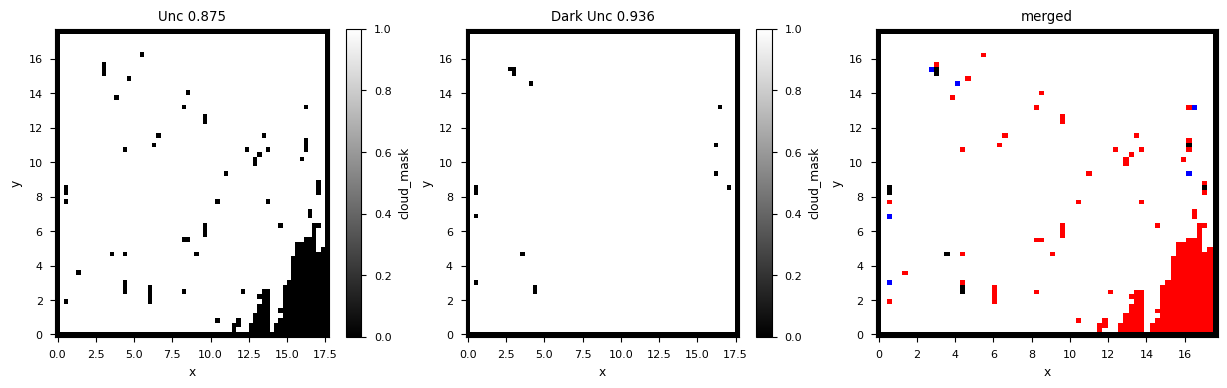

In [9]:
f, ax = plt.subplots(1, 3, figsize=(15,4))

merged = np.zeros((clouds['Unconstrained'].cloud_mask.sizes['x'], clouds['Unconstrained'].cloud_mask.sizes['y'], 3))
merged[(clouds['Unconstrained'].cloud_mask.data == 0) & (clouds['Dark Surf Unc'].cloud_mask.data == 0)] = [0, 0, 0] # black
merged[(clouds['Unconstrained'].cloud_mask.data == 0) & (clouds['Dark Surf Unc'].cloud_mask.data == 1)] = [1, 0, 0] # red
merged[(clouds['Unconstrained'].cloud_mask.data == 1) & (clouds['Dark Surf Unc'].cloud_mask.data == 0)] = [0, 0, 1] # blue
merged[(clouds['Unconstrained'].cloud_mask.data == 1) & (clouds['Dark Surf Unc'].cloud_mask.data == 1)] = [1, 1, 1] # white
merged_cloud = clouds['Unconstrained'].copy(deep=True)
merged_cloud['merged_cm'] = (['x', 'y', 'rbg'], merged)

(clouds['Unconstrained'].cloud_mask).plot(y='y', ax=ax[0], cmap='gray')
(clouds['Dark Surf Unc'].cloud_mask).plot(y='y', ax=ax[1], cmap='gray')
merged_cloud.merged_cm.plot.imshow(y='y', ax=ax[2], cmap='gray')
ax[0].set_title('Unc {:.3f}'.format(clouds['Unconstrained'].cf.data))
ax[1].set_title('Dark Unc {:.3f}'.format(clouds['Dark Surf Unc'].cf.data))
ax[2].set_title('merged')

In [10]:
cvm.cf.data

array(0.82579882)